In [ ]:
from pathlib import Path, PurePosixPath
from email import policy
from email.parser import BytesParser
from email.header import decode_header

import tarfile
import re
import json
import shutil
import pandas as pd

from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split

SEED = 42

archive_names = [
    "20030228_easy_ham.tar.bz2",
    "20030228_easy_ham_2.tar.bz2",
    "20030228_hard_ham.tar.bz2",
    "20030228_spam.tar.bz2",
    "20050311_spam_2.tar.bz2"
]

data_files = [Path("/content") / name for name in archive_names]
missing_files = [file.name for file in data_files if not file.exists()]

if missing_files:
    raise FileNotFoundError(
        "Upload these archives first: " + ", ".join(missing_files)
    )

print("All 5 source archives are available.")

All 5 source archives are available.


In [ ]:
def is_email_file(member):
    return (
        member.isfile()
        and PurePosixPath(member.name).name.split(".")[0].isdigit()
    )


summary = []

for file in data_files:
    with tarfile.open(file, "r:*") as archive:
        count = sum(is_email_file(m) for m in archive.getmembers())

    summary.append({
        "File": file.name,
        "Class": "Spam" if "spam" in file.name.lower() else "Ham",
        "Emails": count
    })

summary_df = pd.DataFrame(summary)
raw_email_count = int(summary_df["Emails"].sum())

display(summary_df)
print("Total source emails:", raw_email_count)

assert raw_email_count == 6046, "Source data differs from the inspected version."

,File,Class,Emails
0,20030228_easy_ham.tar.bz2,Ham,2500
1,20030228_easy_ham_2.tar.bz2,Ham,1400
2,20030228_hard_ham.tar.bz2,Ham,250
3,20030228_spam.tar.bz2,Spam,500
4,20050311_spam_2.tar.bz2,Spam,1396


Total source emails: 6046


In [ ]:
def normalize_spaces(text):
    return re.sub(r"\s+", " ", text).strip()


def html_to_text(html):
    soup = BeautifulSoup(html, "html.parser")

    for element in soup(["script", "style"]):
        element.decompose()

    return soup.get_text(separator=" ", strip=True)


def decode_body_fallback(part):
    payload = part.get_payload(decode=True)

    if payload is None:
        payload = part.get_payload()
        if isinstance(payload, str):
            return payload, "Already decoded"
        raise ValueError("No readable text payload")

    declared = (part.get_content_charset() or "").strip().lower()

    aliases = {
        "chinesebig5": "big5",
        "gb2312_charset": "gb2312"
    }

    charset = aliases.get(declared, declared)
    candidates = list(dict.fromkeys(
        [charset, "utf-8", "windows-1252"]
    ))

    for encoding in candidates:
        if not encoding:
            continue

        try:
            return payload.decode(encoding), encoding
        except (LookupError, UnicodeDecodeError):
            continue

    return (
        payload.decode("utf-8", errors="replace"),
        "utf-8 with replacement"
    )


def extract_email(raw_bytes, use_fallback=False):
    message = BytesParser(
        policy=policy.default
    ).parsebytes(raw_bytes)

    subject = str(message.get("Subject", ""))
    part = message.get_body(preferencelist=("plain", "html"))

    body = ""
    decoding_used = ""

    if part is not None:
        if use_fallback:
            body, decoding_used = decode_body_fallback(part)
        else:
            body = part.get_content()

            if isinstance(body, bytes):
                body = body.decode("utf-8", errors="replace")

        if part.get_content_type() == "text/html":
            body = html_to_text(body)

    elif use_fallback:
        raise ValueError("No readable body found")

    subject = normalize_spaces(subject)
    body = normalize_spaces(body)

    return {
        "subject": subject,
        "body": body,
        "text": (subject + " " + body).strip(),
        "recovery_decoding": decoding_used
    }


rows = []
read_errors = []

# First pass: normal email parsing
for file in data_files:
    label = 1 if "spam" in file.name.lower() else 0

    with tarfile.open(file, "r:*") as archive:
        for member in archive.getmembers():
            if not is_email_file(member):
                continue

            try:
                with archive.extractfile(member) as email_file:
                    result = extract_email(email_file.read())

                rows.append({
                    "source": file.name,
                    "filename": member.name,
                    "label": label,
                    **result
                })

            except Exception as error:
                read_errors.append({
                    "source": file.name,
                    "filename": member.name,
                    "error": str(error)
                })

initial_success_count = len(rows)
recovered_rows = []
remaining_errors = []

# Second pass: retry only messages that failed
for item in read_errors:
    try:
        file = next(
            f for f in data_files if f.name == item["source"]
        )

        with tarfile.open(file, "r:*") as archive:
            with archive.extractfile(item["filename"]) as email_file:
                result = extract_email(
                    email_file.read(),
                    use_fallback=True
                )

        recovered_rows.append({
            "source": item["source"],
            "filename": item["filename"],
            "label": 1 if "spam" in item["source"].lower() else 0,
            **result
        })

    except Exception as error:
        remaining_errors.append({
            **item,
            "error": str(error)
        })

# Preserve the original processing order
df = pd.DataFrame(rows + recovered_rows)

print("Initially read:", initial_success_count)
print("Initial reading errors:", len(read_errors))
print("Recovered emails:", len(recovered_rows))
print("Remaining reading errors:", len(remaining_errors))
print("Total readable emails:", len(df))

assert len(df) + len(remaining_errors) == raw_email_count

if remaining_errors:
    display(pd.DataFrame(remaining_errors))

Initially read: 6019
Initial reading errors: 27
Recovered emails: 26
Remaining reading errors: 1
Total readable emails: 6045


,source,filename,error
0,20030228_spam.tar.bz2,spam/00479.a2cd6780001042d8203b05a6ab0f34ac,invalid literal for int() with base 10: '116er...


In [ ]:
def decode_big5_bytes(value):
    for encoding in ("big5", "cp950"):
        try:
            return value.decode(encoding), encoding
        except UnicodeDecodeError:
            continue

    return (
        value.decode("big5", errors="replace"),
        "big5 with replacement"
    )


target_source = "20050311_spam_2.tar.bz2"
target_filename = "spam_2/00006.3ca1f399ccda5d897fecb8c57669a283"

archive_path = next(
    file for file in data_files if file.name == target_source
)

with tarfile.open(archive_path, "r:*") as archive:
    with archive.extractfile(target_filename) as email_file:
        raw_message = email_file.read()

message = BytesParser(
    policy=policy.compat32
).parsebytes(raw_message)

raw_subject = next(
    (
        value for name, value in message.raw_items()
        if name.lower() == "subject"
    ),
    ""
)

subject_parts = []

for value, charset in decode_header(raw_subject):
    if isinstance(value, bytes):
        encoding = (charset or "").lower()

        if encoding and encoding not in (
            "chinesebig5", "big5", "unknown-8bit"
        ):
            try:
                decoded = value.decode(encoding)
            except (LookupError, UnicodeDecodeError):
                decoded, _ = decode_big5_bytes(value)
        else:
            decoded, _ = decode_big5_bytes(value)

    else:
        original_bytes = value.encode(
            "utf-8", errors="surrogateescape"
        )
        decoded, _ = decode_big5_bytes(original_bytes)

    subject_parts.append(decoded)

part = next(
    p for p in message.walk()
    if p.get_content_type() == "text/html"
)

body_html, encoding_used = decode_big5_bytes(
    part.get_payload(decode=True)
)

subject = normalize_spaces(" ".join(subject_parts))
body = normalize_spaces(html_to_text(body_html))
text = (subject + " " + body).strip()

mask = (
    (df["source"] == target_source)
    & (df["filename"] == target_filename)
)

assert mask.sum() == 1, "Expected exactly one target message."

df.loc[mask, "subject"] = subject
df.loc[mask, "body"] = body
df.loc[mask, "text"] = text
df.loc[mask, "recovery_decoding"] = encoding_used

print("Encoding used:", encoding_used)
print("Replacement characters in final text:", text.count("\ufffd"))
print("Subject:", subject)
print("Body preview:", body[:300])

Encoding used: big5 with replacement
Replacement characters in final text: 0
Subject: 還在用20%的信用卡循環嗎??? Time:PM 05:36:34
Body preview: cpurf 6 您還在用 20 % 的信用卡嗎 !!! 零利率代償 時代來臨囉~~ 目前循環總額 x 信用卡利率 x 1/12 = 「1 個月利息」費用 $100,000 x 20% x 1/12= $1,667 …它行利息 $100,000 x 0 % x 1/12= $0 …本行利息 唯一只收取手續費為核准代償金額之 1 % 即 $100,000 x 1 % = $1000 $1667-$1000=$667 第一個月即可幫您省下667元 代償十萬元，前十五個月每月最低應繳為 $1000 元 另有許多優惠專案供您選擇!!! 請填妥下列表格， 我們將為您寄一份更詳細之資料及申請書給您！ 或電洽


In [ ]:
df_before_cleaning = df.copy()

text_keys = (
    df["text"]
    .fillna("")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

audit_df = df.assign(text_key=text_keys)
empty_mask = audit_df["text_key"].eq("")
nonempty_df = audit_df.loc[~empty_mask]

label_counts = nonempty_df.groupby("text_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index

print("Empty texts:", int(empty_mask.sum()))
print("Texts with conflicting labels:", len(conflicting_keys))

if len(conflicting_keys) > 0:
    raise ValueError(
        "Conflicting labels found. Inspect them before deduplication."
    )

duplicate_count = int(
    nonempty_df["text_key"].duplicated().sum()
)

clean_df = (
    nonempty_df
    .drop_duplicates(subset="text_key", keep="first")
    .drop(columns="text_key")
    .reset_index(drop=True)
)

print("Duplicate copies removed:", duplicate_count)
print("Prepared emails:", len(clean_df))

class_summary = (
    clean_df["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("label")
    .reset_index(name="emails")
)

class_summary["class"] = class_summary["label"].map({
    0: "Ham",
    1: "Spam"
})

class_summary["percentage"] = (
    class_summary["emails"] / len(clean_df) * 100
).round(2)

display(class_summary[["class", "emails", "percentage"]])

assert len(clean_df) == 5915, (
    "Prepared count differs from the previous run. "
    "Check the parsing outputs before continuing."
)
assert clean_df["text"].str.strip().ne("").all()

Empty texts: 0
Texts with conflicting labels: 0
Duplicate copies removed: 130
Prepared emails: 5915


,class,emails,percentage
0,Ham,4108,69.45
1,Spam,1807,30.55


In [ ]:
train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,
    random_state=SEED,
    stratify=clean_df["label"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Total": len(frame),
        "Ham": int((frame["label"] == 0).sum()),
        "Spam": int((frame["label"] == 1).sum())
    }
    for name, frame in [
        ("Training / development", train_df),
        ("Final test", test_df)
    ]
])

display(split_summary)

assert set(train_df["text"]).isdisjoint(set(test_df["text"]))
assert len(train_df) + len(test_df) == len(clean_df)

print("Checks passed: no identical texts shared between the two sets.")
print("The final test set is reserved for final evaluation.")

,Split,Total,Ham,Spam
0,Training / development,4732,3286,1446
1,Final test,1183,822,361


Checks passed: no identical texts shared between the two sets.
The final test set is reserved for final evaluation.


In [ ]:
from google.colab import files

output_dir = Path("/content/spam_data_prepared")
output_dir.mkdir(exist_ok=True)

clean_df.to_csv(output_dir / "clean_emails.csv", index=False)
train_df.to_csv(output_dir / "train.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

error_columns = ["source", "filename", "error"]

pd.DataFrame(
    read_errors, columns=error_columns
).to_csv(output_dir / "initial_reading_errors.csv", index=False)

pd.DataFrame(
    remaining_errors, columns=error_columns
).to_csv(output_dir / "excluded_reading_errors.csv", index=False)

df.loc[
    df["recovery_decoding"].fillna("").ne(""),
    ["source", "filename", "recovery_decoding"]
].to_csv(output_dir / "recovery_log.csv", index=False)

metadata = {
    "dataset": "SpamAssassin Public Corpus",
    "source_url": "https://spamassassin.apache.org/old/publiccorpus/",
    "source_archives": archive_names,
    "random_seed": SEED,
    "test_fraction": 0.20,
    "stratified_split": True,
    "labels": {"0": "Ham", "1": "Spam"},
    "emails_before_reading": raw_email_count,
    "initial_reading_errors": len(read_errors),
    "recovered_emails": len(recovered_rows),
    "excluded_reading_errors": len(remaining_errors),
    "empty_texts_removed": int(empty_mask.sum()),
    "duplicate_copies_removed": duplicate_count,
    "prepared_emails": len(clean_df),
    "training_emails": len(train_df),
    "test_emails": len(test_df),
    "text_processing": [
        "Extract subject and preferred plain-text or HTML body",
        "Convert HTML body to text",
        "Normalize whitespace",
        "Retry decoding failures using documented fallback encodings",
        "Repair the inspected Big5 message from its original bytes",
        "Exclude remaining reading failures and record their details",
        "Check for conflicting labels before deduplication",
        "Remove exact duplicate texts after whitespace normalization"
    ],
    "limitations": [
        "Fallback decoding may change some characters",
        "Near-duplicate texts have not been removed"
    ]
}

with open(output_dir / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

zip_path = shutil.make_archive(
    "/content/spam_data_prepared",
    "zip",
    root_dir=output_dir
)

print("Prepared data and logs saved successfully.")
files.download(zip_path)

Prepared data and logs saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# DATA PREPARATION COMPLETED
# ============================================================
# Emails have been extracted, decoding issues handled,
# and duplicate texts removed.
#
# Prepared dataset: 5,915 emails
# Training/development set: 4,732 emails
# Reserved final test set: 1,183 emails
#
# Next: model development and 5-fold cross-validation.
# The final test set will not be used for model selection.
# ============================================================

In [ ]:
# ============================================================
# MODEL 1: LOGISTIC REGRESSION + TF-IDF
# Baseline model — 5-fold cross-validation
# ============================================================

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use training/development data only
X_train = train_df["text"]
y_train = train_df["label"]

# Reuse these exact folds for the other models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(cv.split(X_train, y_train))


def false_positive_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fp / (fp + tn) if (fp + tn) else 0.0


# Spam (label 1) is the positive class
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "fpr": make_scorer(
        false_positive_rate, greater_is_better=False
    )
}

# The pipeline fits TF-IDF only on each fold's training portion
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        lowercase=True
    )),
    ("model", LogisticRegression(
        C=1.0,
        solver="liblinear",
        max_iter=2000,
        random_state=SEED
    ))
])

print("Running Logistic Regression: 5-fold cross-validation...")

lr_cv = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    n_jobs=1,
    error_score="raise"
)

# Convert the negative FPR scores back to positive rates
lr_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": lr_cv["test_accuracy"],
    "Precision": lr_cv["test_precision"],
    "Recall": lr_cv["test_recall"],
    "F1": lr_cv["test_f1"],
    "FPR": -lr_cv["test_fpr"],
    "Fit time (seconds)": lr_cv["fit_time"]
})

print("\nResults for each fold:")
display(lr_fold_results.round(4))

metric_columns = ["Accuracy", "Precision", "Recall", "F1", "FPR"]

lr_summary = pd.DataFrame({
    "Mean": lr_fold_results[metric_columns].mean(),
    "Standard deviation": (
        lr_fold_results[metric_columns].std(ddof=1)
    )
})

print("\nCross-validation summary — metric scale: 0 to 1")
display(lr_summary.round(4))

# Save results in the current Colab session
results_dir = Path("/content/model_results")
results_dir.mkdir(exist_ok=True)

lr_fold_results.to_csv(
    results_dir / "lr_cv_folds.csv", index=False
)
lr_summary.to_csv(
    results_dir / "lr_cv_summary.csv",
    index_label="Metric"
)

print("\nCompleted. The reserved final test set was not used.")

Running Logistic Regression: 5-fold cross-validation...

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1,FPR,Fit time (seconds)
0,1,0.9704,0.9780,0.9239,0.9502,0.0091,3.9110
1,2,0.9715,0.9747,0.9310,0.9524,0.0107,4.8201
2,3,0.9715,0.9712,0.9343,0.9524,0.0122,3.7387
3,4,0.9672,0.9850,0.9066,0.9441,0.0061,3.7615
4,5,0.9693,0.9710,0.9273,0.9487,0.0122,5.0827



Cross-validation summary — metric scale: 0 to 1


,Mean,Standard deviation
Accuracy,0.9700,0.0018
Precision,0.9760,0.0058
Recall,0.9246,0.0108
F1,0.9496,0.0034
FPR,0.0100,0.0025



Completed. The reserved final test set was not used.


In [ ]:
# ============================================================
# MODEL 2: LINEAR SVM + TF-IDF
# Same data, folds, TF-IDF settings, and evaluation metrics
# ============================================================

from sklearn.svm import LinearSVC

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        lowercase=True
    )),
    ("model", LinearSVC(
        C=1.0,
        dual=True,
        max_iter=10000,
        random_state=SEED
    ))
])

print("Running Linear SVM: 5-fold cross-validation...")

svm_cv = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    n_jobs=1,
    error_score="raise"
)

svm_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": svm_cv["test_accuracy"],
    "Precision": svm_cv["test_precision"],
    "Recall": svm_cv["test_recall"],
    "F1": svm_cv["test_f1"],
    "FPR": -svm_cv["test_fpr"],
    "Fit time (seconds)": svm_cv["fit_time"]
})

print("\nResults for each fold:")
display(svm_fold_results.round(4))

svm_summary = pd.DataFrame({
    "Mean": svm_fold_results[metric_columns].mean(),
    "Standard deviation": (
        svm_fold_results[metric_columns].std(ddof=1)
    )
})

print("\nCross-validation summary — metric scale: 0 to 1")
display(svm_summary.round(4))

comparison_ml = pd.DataFrame({
    "Logistic Regression": lr_summary["Mean"],
    "Linear SVM": svm_summary["Mean"]
})

print("\nInitial comparison — mean cross-validation scores:")
display(comparison_ml.round(4))

svm_fold_results.to_csv(
    results_dir / "svm_cv_folds.csv", index=False
)
svm_summary.to_csv(
    results_dir / "svm_cv_summary.csv",
    index_label="Metric"
)
comparison_ml.to_csv(
    results_dir / "ml_cv_comparison.csv",
    index_label="Metric"
)

print("\nCompleted. The reserved final test set was not used.")

Running Linear SVM: 5-fold cross-validation...

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1,FPR,Fit time (seconds)
0,1,0.9789,0.9686,0.9619,0.9653,0.0137,3.9367
1,2,0.9820,0.9789,0.9621,0.9704,0.0091,3.7887
2,3,0.9810,0.9625,0.9758,0.9691,0.0167,4.8656
3,4,0.9820,0.9857,0.9550,0.9701,0.0061,3.8244
4,5,0.9820,0.9658,0.9758,0.9707,0.0152,4.1295



Cross-validation summary — metric scale: 0 to 1


,Mean,Standard deviation
Accuracy,0.9812,0.0014
Precision,0.9723,0.0097
Recall,0.9661,0.0093
F1,0.9691,0.0022
FPR,0.0122,0.0044



Initial comparison — mean cross-validation scores:


,Logistic Regression,Linear SVM
Accuracy,0.9700,0.9812
Precision,0.9760,0.9723
Recall,0.9246,0.9661
F1,0.9496,0.9691
FPR,0.0100,0.0122



Completed. The reserved final test set was not used.


In [ ]:

# PREPARE FOR MODEL 3: TEXT CNN
# Check TensorFlow and GPU availability
# Back up the completed ML cross-validation results


import tensorflow as tf
from google.colab import files

print("TensorFlow version:", tf.__version__)

gpu_devices = tf.config.list_physical_devices("GPU")

print("Available GPUs:", len(gpu_devices))

if gpu_devices:
    print("GPU detected. CNN training can use GPU acceleration.")
else:
    print("No GPU detected. CNN can run on CPU, but may take longer.")

# Save a local backup before any runtime changes
results_zip = shutil.make_archive(
    "/content/ml_cv_results",
    "zip",
    root_dir=results_dir
)

files.download(results_zip)

print("\nML results backup downloaded.")


TensorFlow version: 2.21.0
Available GPUs: 0
No GPU detected. CNN can run on CPU, but may take longer.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ML results backup downloaded.


In [ ]:
# ============================================================
# MODEL 3: TEXT CNN
# Same cross-validation folds and evaluation metrics
# ============================================================

import time
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Fixed initial settings
MAX_TOKENS = 5000
MAX_LENGTH = 300
EMBEDDING_DIM = 64
FILTERS = 64
KERNEL_SIZE = 5
BATCH_SIZE = 32
EPOCHS = 5
LEARNING_RATE = 0.001

# Improve repeatability in the same software/hardware environment
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

cnn_rows = []
cnn_histories = []

for fold, (fit_indices, val_indices) in enumerate(cv_splits, start=1):
    print(f"\n{'=' * 50}")
    print(f"CNN — Fold {fold}/5")
    print(f"{'=' * 50}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold)

    fit_text = X_train.iloc[fit_indices].astype(str).to_numpy()
    val_text = X_train.iloc[val_indices].astype(str).to_numpy()

    fit_labels = y_train.iloc[fit_indices].to_numpy(dtype="float32")
    val_labels = y_train.iloc[val_indices].to_numpy(dtype="int32")

    start_time = time.perf_counter()

    # Learn the vocabulary from this fold's training portion only
    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=MAX_TOKENS,
        standardize="lower_and_strip_punctuation",
        split="whitespace",
        output_mode="int",
        output_sequence_length=MAX_LENGTH
    )

    vocabulary_data = tf.data.Dataset.from_tensor_slices(
        fit_text
    ).batch(128)

    vectorizer.adapt(vocabulary_data)

    fit_sequences = vectorizer(
        tf.constant(fit_text)
    ).numpy()

    # The vocabulary remains fixed when transforming validation text
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(MAX_LENGTH,), dtype="int64"),
        tf.keras.layers.Embedding(
            input_dim=len(vectorizer.get_vocabulary()),
            output_dim=EMBEDDING_DIM
        ),
        tf.keras.layers.Conv1D(
            filters=FILTERS,
            kernel_size=KERNEL_SIZE,
            activation="relu"
        ),
        tf.keras.layers.GlobalMaxPooling1D(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Fixed epoch count: validation labels are not used for training
    history = model.fit(
        fit_sequences,
        fit_labels,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        shuffle=True,
        verbose=2
    )

    fit_time = time.perf_counter() - start_time

    val_sequences = vectorizer(
        tf.constant(val_text)
    ).numpy()

    probabilities = model.predict(
        val_sequences,
        batch_size=128,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    fold_result = {
        "Fold": fold,
        "Accuracy": accuracy_score(val_labels, predictions),
        "Precision": precision_score(
            val_labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            val_labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            val_labels, predictions, zero_division=0
        ),
        "FPR": false_positive_rate(val_labels, predictions),
        "Fit time (seconds)": fit_time
    }

    cnn_rows.append(fold_result)

    for epoch in range(EPOCHS):
        cnn_histories.append({
            "Fold": fold,
            "Epoch": epoch + 1,
            "Training loss": history.history["loss"][epoch],
            "Training accuracy": history.history["accuracy"][epoch]
        })

    print(f"Fold {fold} validation F1: {fold_result['F1']:.4f}")

    # Save progress after each completed fold
    pd.DataFrame(cnn_rows).to_csv(
        results_dir / "cnn_cv_folds.csv", index=False
    )

    pd.DataFrame(cnn_histories).to_csv(
        results_dir / "cnn_training_history.csv", index=False
    )

cnn_fold_results = pd.DataFrame(cnn_rows)

cnn_summary = pd.DataFrame({
    "Mean": cnn_fold_results[metric_columns].mean(),
    "Standard deviation": (
        cnn_fold_results[metric_columns].std(ddof=1)
    )
})

print("\nCNN cross-validation summary — metric scale: 0 to 1")
display(cnn_summary.round(4))

comparison_all = pd.DataFrame({
    "Logistic Regression": lr_summary["Mean"],
    "Linear SVM": svm_summary["Mean"],
    "Text CNN": cnn_summary["Mean"]
})

print("\nInitial comparison across all three models:")
display(comparison_all.round(4))

cnn_summary.to_csv(
    results_dir / "cnn_cv_summary.csv",
    index_label="Metric"
)

comparison_all.to_csv(
    results_dir / "all_models_cv_comparison.csv",
    index_label="Metric"
)

print("\nCompleted. The reserved final test set was not used.")


CNN — Fold 1/5
Epoch 1/5
119/119 - 6s - 47ms/step - accuracy: 0.7939 - loss: 0.4128
Epoch 2/5
119/119 - 5s - 46ms/step - accuracy: 0.9667 - loss: 0.1112
Epoch 3/5
119/119 - 5s - 43ms/step - accuracy: 0.9871 - loss: 0.0512
Epoch 4/5
119/119 - 4s - 38ms/step - accuracy: 0.9966 - loss: 0.0213
Epoch 5/5
119/119 - 6s - 51ms/step - accuracy: 0.9979 - loss: 0.0112
Fold 1 validation F1: 0.9655

CNN — Fold 2/5
Epoch 1/5
119/119 - 6s - 48ms/step - accuracy: 0.7918 - loss: 0.4349
Epoch 2/5
119/119 - 7s - 56ms/step - accuracy: 0.9620 - loss: 0.1052
Epoch 3/5
119/119 - 5s - 38ms/step - accuracy: 0.9923 - loss: 0.0369
Epoch 4/5
119/119 - 5s - 42ms/step - accuracy: 0.9979 - loss: 0.0122
Epoch 5/5
119/119 - 6s - 47ms/step - accuracy: 0.9995 - loss: 0.0060
Fold 2 validation F1: 0.9565

CNN — Fold 3/5
Epoch 1/5
119/119 - 6s - 53ms/step - accuracy: 0.7971 - loss: 0.4305
Epoch 2/5
119/119 - 5s - 46ms/step - accuracy: 0.9662 - loss: 0.1085
Epoch 3/5
119/119 - 5s - 39ms/step - accuracy: 0.9892 - loss: 0.04

,Mean,Standard deviation
Accuracy,0.9740,0.0031
Precision,0.9584,0.0053
Recall,0.9564,0.0086
F1,0.9574,0.0052
FPR,0.0183,0.0024



Initial comparison across all three models:


,Logistic Regression,Linear SVM,Text CNN
Accuracy,0.9700,0.9812,0.9740
Precision,0.9760,0.9723,0.9584
Recall,0.9246,0.9661,0.9564
F1,0.9496,0.9691,0.9574
FPR,0.0100,0.0122,0.0183



Completed. The reserved final test set was not used.


In [ ]:
# ============================================================
# BACK UP CROSS-VALIDATION RESULTS FOR ALL THREE MODELS
# ============================================================

import json
import platform
import sklearn
from google.colab import files

experiment_settings = {
    "seed": SEED,
    "cv_folds": 5,
    "primary_metric": "Spam-class F1",
    "final_test_used": False,
    "tfidf": {
        "max_features": 5000,
        "ngram_range": [1, 2],
        "lowercase": True
    },
    "logistic_regression": {
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 2000
    },
    "linear_svm": {
        "C": 1.0,
        "dual": True,
        "max_iter": 10000
    },
    "cnn": {
        "max_tokens": MAX_TOKENS,
        "max_length": MAX_LENGTH,
        "embedding_dim": EMBEDDING_DIM,
        "filters": FILTERS,
        "kernel_size": KERNEL_SIZE,
        "dense_units": 32,
        "dropout": 0.3,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "prediction_threshold": 0.5,
        "fold_seed_rule": "SEED + fold_number"
    },
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "tensorflow": tf.__version__
    }
}

with open(
    results_dir / "experiment_settings.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(experiment_settings, file, indent=2)

# Save each training email's validation fold assignment
fold_assignments = train_df[["source", "filename", "label"]].copy()
fold_assignments["validation_fold"] = 0

for fold, (_, val_indices) in enumerate(cv_splits, start=1):
    fold_assignments.loc[val_indices, "validation_fold"] = fold

fold_assignments.to_csv(
    results_dir / "cv_fold_assignments.csv",
    index=False
)

backup_path = shutil.make_archive(
    "/content/all_models_cv_results",
    "zip",
    root_dir=results_dir
)

files.download(backup_path)

print("All three models' CV results and settings have been backed up.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All three models' CV results and settings have been backed up.


In [ ]:
# ============================================================
# FINAL TRAINING AND HELD-OUT TEST EVALUATION
# Fixed settings for all three models
# ============================================================

from sklearn.base import clone
from sklearn.metrics import confusion_matrix
import time
import numpy as np

X_test = test_df["text"]
y_test = test_df["label"].to_numpy()

final_rows = []
final_confusion_matrices = {}

final_predictions = test_df[
    ["source", "filename", "label"]
].copy()


def record_final_results(name, predictions, fit_seconds):
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "FPR": false_positive_rate(y_test, predictions),
        "Fit time (seconds)": fit_seconds
    })

    matrix = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )
    final_confusion_matrices[name] = matrix
    final_predictions[name] = predictions

    print(f"\n{name} — confusion matrix")
    display(pd.DataFrame(
        matrix,
        index=["Actual Ham", "Actual Spam"],
        columns=["Predicted Ham", "Predicted Spam"]
    ))


# ------------------------------------------------------------
# 1. Logistic Regression
# ------------------------------------------------------------

print("Training Logistic Regression on all training data...")

final_lr = clone(lr_pipeline)

start = time.perf_counter()
final_lr.fit(X_train, y_train)
lr_fit_seconds = time.perf_counter() - start

lr_test_predictions = final_lr.predict(X_test)

record_final_results(
    "Logistic Regression",
    lr_test_predictions,
    lr_fit_seconds
)


# ------------------------------------------------------------
# 2. Linear SVM
# ------------------------------------------------------------

print("\nTraining Linear SVM on all training data...")

final_svm = clone(svm_pipeline)

start = time.perf_counter()
final_svm.fit(X_train, y_train)
svm_fit_seconds = time.perf_counter() - start

svm_test_predictions = final_svm.predict(X_test)

record_final_results(
    "Linear SVM",
    svm_test_predictions,
    svm_fit_seconds
)


# ------------------------------------------------------------
# 3. Text CNN
# ------------------------------------------------------------

print("\nTraining Text CNN on all training data...")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

training_texts = X_train.astype(str).to_numpy()
test_texts = X_test.astype(str).to_numpy()
training_labels = y_train.to_numpy(dtype="float32")

start = time.perf_counter()

final_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn the vocabulary from training data only
final_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        training_texts
    ).batch(128)
)

training_sequences = final_vectorizer(
    tf.constant(training_texts)
).numpy()

final_cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(MAX_LENGTH,), dtype="int64"),
    tf.keras.layers.Embedding(
        input_dim=len(final_vectorizer.get_vocabulary()),
        output_dim=EMBEDDING_DIM
    ),
    tf.keras.layers.Conv1D(
        filters=FILTERS,
        kernel_size=KERNEL_SIZE,
        activation="relu"
    ),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

final_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

final_cnn_history = final_cnn.fit(
    training_sequences,
    training_labels,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=2
)

cnn_fit_seconds = time.perf_counter() - start

# Transform test text using the fixed training vocabulary
test_sequences = final_vectorizer(
    tf.constant(test_texts)
).numpy()

cnn_test_probabilities = final_cnn.predict(
    test_sequences,
    batch_size=128,
    verbose=0
).ravel()

cnn_test_predictions = (
    cnn_test_probabilities >= 0.5
).astype(int)

record_final_results(
    "Text CNN",
    cnn_test_predictions,
    cnn_fit_seconds
)

final_predictions["CNN spam probability"] = cnn_test_probabilities


# ------------------------------------------------------------
# Save final evaluation results
# ------------------------------------------------------------

final_results = pd.DataFrame(final_rows)

print("\nFINAL TEST RESULTS — metric scale: 0 to 1")
display(final_results.round(4))

final_results.to_csv(
    results_dir / "final_test_results.csv",
    index=False
)

final_predictions.to_csv(
    results_dir / "final_test_predictions.csv",
    index=False
)

pd.DataFrame(final_cnn_history.history).rename_axis(
    "epoch_index"
).to_csv(results_dir / "cnn_final_training_history.csv")

for name, matrix in final_confusion_matrices.items():
    filename = name.lower().replace(" ", "_")

    pd.DataFrame(
        matrix,
        index=["Actual Ham", "Actual Spam"],
        columns=["Predicted Ham", "Predicted Spam"]
    ).to_csv(results_dir / f"{filename}_test_confusion_matrix.csv")

print("\nFinal evaluation completed and saved in this session.")

Training Logistic Regression on all training data...

Logistic Regression — confusion matrix


,Predicted Ham,Predicted Spam
Actual Ham,814,8
Actual Spam,23,338



Training Linear SVM on all training data...

Linear SVM — confusion matrix


,Predicted Ham,Predicted Spam
Actual Ham,814,8
Actual Spam,4,357



Training Text CNN on all training data...
Epoch 1/5
148/148 - 8s - 54ms/step - accuracy: 0.8121 - loss: 0.3940
Epoch 2/5
148/148 - 11s - 74ms/step - accuracy: 0.9643 - loss: 0.1029
Epoch 3/5
148/148 - 9s - 63ms/step - accuracy: 0.9899 - loss: 0.0403
Epoch 4/5
148/148 - 6s - 44ms/step - accuracy: 0.9970 - loss: 0.0140
Epoch 5/5
148/148 - 6s - 38ms/step - accuracy: 0.9996 - loss: 0.0050

Text CNN — confusion matrix


,Predicted Ham,Predicted Spam
Actual Ham,808,14
Actual Spam,14,347



FINAL TEST RESULTS — metric scale: 0 to 1


,Model,Accuracy,Precision,Recall,F1,FPR,Fit time (seconds)
0,Logistic Regression,0.9738,0.9769,0.9363,0.9562,0.0097,5.7514
1,Linear SVM,0.9899,0.9781,0.9889,0.9835,0.0097,4.4885
2,Text CNN,0.9763,0.9612,0.9612,0.9612,0.0170,46.3371



Final evaluation completed and saved in this session.


In [ ]:
# ============================================================
# SAVE FINAL MODELS AND BACK UP ALL RESULTS
# ============================================================

import json
import shutil
import joblib
from pathlib import Path
from google.colab import files

backup_dir = Path("/content/spam_final_backup")
models_dir = backup_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save ML pipelines, including their fitted TF-IDF vectorizers
joblib.dump(
    final_lr,
    models_dir / "logistic_regression_pipeline.joblib"
)

joblib.dump(
    final_svm,
    models_dir / "linear_svm_pipeline.joblib"
)

# Save the trained CNN
final_cnn.save(models_dir / "text_cnn.keras")

# Save the vocabulary in its original order
with open(
    models_dir / "cnn_vocabulary.json", "w", encoding="utf-8"
) as file:
    json.dump(
        final_vectorizer.get_vocabulary(),
        file,
        ensure_ascii=False,
        indent=2
    )

# Save the CNN text-processing settings
cnn_preprocessing = {
    "max_tokens": MAX_TOKENS,
    "output_sequence_length": MAX_LENGTH,
    "standardize": "lower_and_strip_punctuation",
    "split": "whitespace",
    "output_mode": "int",
    "prediction_threshold": 0.5,
    "final_training_seed": SEED,
    "input_text": "Prepared subject plus body",
    "labels": {"0": "Ham", "1": "Spam"}
}

with open(
    models_dir / "cnn_preprocessing.json", "w", encoding="utf-8"
) as file:
    json.dump(cnn_preprocessing, file, indent=2)

# Copy cross-validation and final test results
shutil.copytree(
    results_dir,
    backup_dir / "results",
    dirs_exist_ok=True
)

# Update the copied settings to reflect completed final testing
settings_path = backup_dir / "results" / "experiment_settings.json"

if settings_path.exists():
    with open(settings_path, encoding="utf-8") as file:
        settings = json.load(file)

    settings["final_test_used"] = True
    settings["final_training_seed"] = SEED

    with open(settings_path, "w", encoding="utf-8") as file:
        json.dump(settings, file, indent=2)

print("Final test results:")
display(final_results.round(4))

zip_path = shutil.make_archive(
    "/content/spam_final_backup",
    "zip",
    root_dir=backup_dir
)

print("Final models and results saved. Downloading backup...")
files.download(zip_path)

Final test results:


,Model,Accuracy,Precision,Recall,F1,FPR,Fit time (seconds)
0,Logistic Regression,0.9738,0.9769,0.9363,0.9562,0.0097,5.7514
1,Linear SVM,0.9899,0.9781,0.9889,0.9835,0.0097,4.4885
2,Text CNN,0.9763,0.9612,0.9612,0.9612,0.0170,46.3371


Final models and results saved. Downloading backup...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Verification passed: all metrics match the confusion matrices.


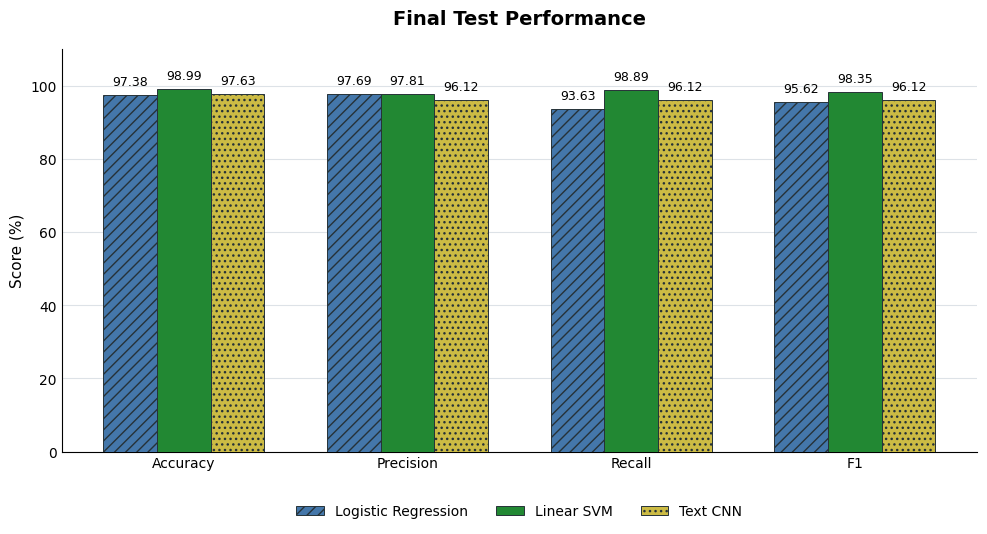

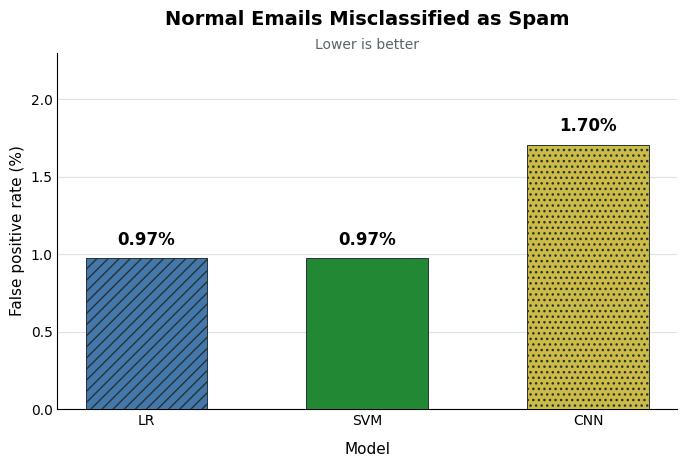

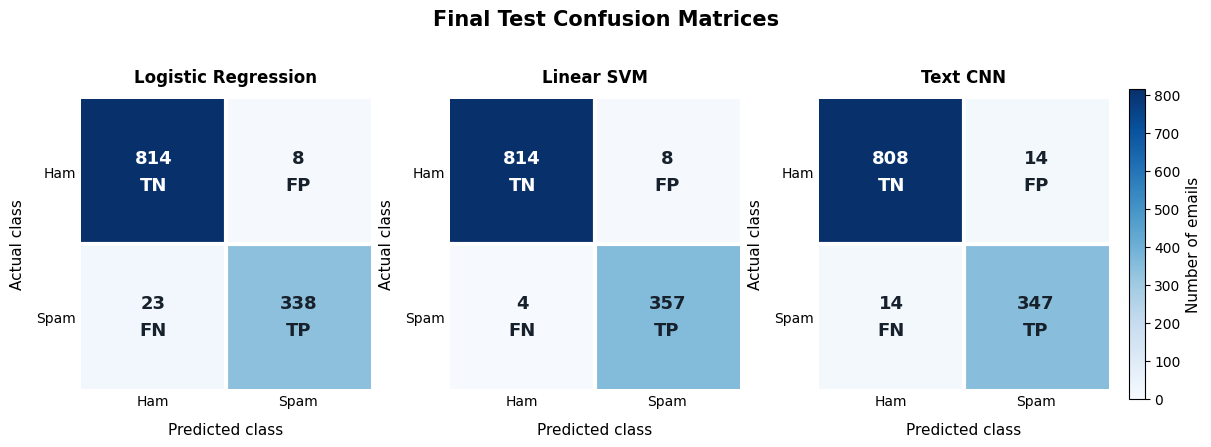

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Updated figures saved as PDF and 300-dpi PNG.
Only the visual styling changed; the results are unchanged.


In [ ]:
# ============================================================
# STYLED REPORT FIGURES — VERIFIED FINAL TEST RESULTS
# No retraining, no changes to predictions or metric values
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import shutil
from google.colab import files

figures_dir = Path("/content/report_figures")
figures_dir.mkdir(exist_ok=True)

model_names = [
    "Logistic Regression",
    "Linear SVM",
    "Text CNN"
]

short_names = ["LR", "SVM", "CNN"]
colors = ["#4477AA", "#228833", "#CCBB44"]
hatches = ["///", "", "..."]

plot_results = final_results.set_index("Model").loc[model_names]


# ------------------------------------------------------------
# Verify that reported metrics match the confusion matrices
# ------------------------------------------------------------

for name in model_names:
    matrix = np.asarray(final_confusion_matrices[name])
    assert matrix.shape == (2, 2), f"Invalid matrix shape: {name}"

    tn, fp, fn, tp = matrix.ravel()

    assert matrix.sum() == len(test_df), (
        f"Test sample count mismatch: {name}"
    )

    calculated = {
        "Accuracy": (tp + tn) / matrix.sum(),
        "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "F1": 2 * tp / (2 * tp + fp + fn)
              if (2 * tp + fp + fn) else 0.0,
        "FPR": fp / (fp + tn) if (fp + tn) else 0.0
    }

    for metric, value in calculated.items():
        assert np.isclose(
            float(plot_results.loc[name, metric]),
            value,
            rtol=0,
            atol=1e-8
        ), f"Metric mismatch: {name} / {metric}"

print("Verification passed: all metrics match the confusion matrices.")


# ------------------------------------------------------------
# Shared visual style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42
})


def save_figure(fig, filename):
    fig.savefig(
        figures_dir / f"{filename}.pdf",
        bbox_inches="tight"
    )
    fig.savefig(
        figures_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )


# ------------------------------------------------------------
# Figure 1: Accuracy, Precision, Recall, and F1
# ------------------------------------------------------------

metrics = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metrics))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, name in enumerate(model_names):
    # Convert proportions to percentages for display only
    values = (
        plot_results.loc[name, metrics].to_numpy(dtype=float) * 100
    )

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=name,
        color=colors[i],
        edgecolor="#263238",
        linewidth=0.7,
        hatch=hatches[i],
        zorder=3
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.2f}" for value in values],
        padding=5,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 110)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_title("Final Test Performance", pad=18)

ax.grid(axis="y", color="#DDE2E7", linewidth=0.8)
ax.tick_params(axis="both", length=0)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3
)

fig.tight_layout()
save_figure(fig, "final_test_metrics")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Figure 2: False positive rate — lower is better
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4.8))

fpr_values = (
    plot_results["FPR"].to_numpy(dtype=float) * 100
)

bars = ax.bar(
    short_names,
    fpr_values,
    width=0.55,
    color=colors,
    edgecolor="#263238",
    linewidth=0.7,
    zorder=3
)

for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in fpr_values],
    padding=7,
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel("False positive rate (%)")
ax.set_xlabel("Model", labelpad=10)
ax.set_title("Normal Emails Misclassified as Spam", pad=20)

ax.text(
    0.5, 1.01,
    "Lower is better",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#59636E"
)

ax.set_ylim(0, max(0.5, float(fpr_values.max()) * 1.35))
ax.grid(axis="y", color="#DDE2E7", linewidth=0.8)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
save_figure(fig, "final_test_fpr")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Figure 3: Confusion matrices with counts and cell labels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4.5),
    layout="constrained"
)

max_count = max(
    np.asarray(final_confusion_matrices[name]).max()
    for name in model_names
)

cell_labels = np.array([
    ["TN", "FP"],
    ["FN", "TP"]
])

cmap = plt.get_cmap("Blues")

for ax, name in zip(axes, model_names):
    matrix = np.asarray(final_confusion_matrices[name])

    heatmap = ax.imshow(
        matrix,
        cmap=cmap,
        vmin=0,
        vmax=max_count,
        interpolation="nearest"
    )

    for row in range(2):
        for col in range(2):
            value = int(matrix[row, col])

            # Select readable text color from the cell background
            red, green, blue, _ = cmap(value / max_count)
            brightness = (
                0.2126 * red + 0.7152 * green + 0.0722 * blue
            )
            text_color = "white" if brightness < 0.5 else "#17212B"

            ax.text(
                col,
                row,
                f"{value}\n{cell_labels[row, col]}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=13,
                fontweight="bold",
                linespacing=1.6
            )

    ax.set_xticks([0, 1], labels=["Ham", "Spam"])
    ax.set_yticks([0, 1], labels=["Ham", "Spam"])
    ax.set_xlabel("Predicted class", labelpad=10)
    ax.set_ylabel("Actual class", labelpad=8)
    ax.set_title(name, fontsize=12, pad=12)
    ax.tick_params(axis="both", length=0)

    # Add clear boundaries between the four cells
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=3)
    ax.tick_params(which="minor", bottom=False, left=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Final Test Confusion Matrices",
    fontsize=15,
    fontweight="bold"
)

colorbar = fig.colorbar(
    heatmap,
    ax=axes.tolist(),
    shrink=0.75,
    pad=0.02
)
colorbar.set_label("Number of emails")

save_figure(fig, "final_test_confusion_matrices")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Download the updated figures
# ------------------------------------------------------------

figures_zip = shutil.make_archive(
    "/content/report_figures",
    "zip",
    root_dir=figures_dir
)

files.download(figures_zip)

print("Updated figures saved as PDF and 300-dpi PNG.")
print("Only the visual styling changed; the results are unchanged.")

In [ ]:
# ============================================================
# ERROR ANALYSIS — FINAL TEST PREDICTIONS
# For discussion only; do not tune models using these examples
# ============================================================

model_names = [
    "Logistic Regression",
    "Linear SVM",
    "Text CNN"
]

# Match predictions to email text using source identifiers
analysis_df = final_predictions.merge(
    test_df[["source", "filename", "subject", "text"]],
    on=["source", "filename"],
    how="left",
    validate="one_to_one"
)

assert len(analysis_df) == len(test_df)
assert analysis_df["text"].notna().all()

error_frames = []
error_counts = []

for model_name in model_names:
    wrong = analysis_df.loc[
        analysis_df[model_name] != analysis_df["label"]
    ].copy()

    wrong["Model"] = model_name
    wrong["Predicted label"] = wrong[model_name]

    wrong["Error type"] = np.where(
        wrong["label"] == 0,
        "False Positive: Ham predicted as Spam",
        "False Negative: Spam predicted as Ham"
    )

    error_frames.append(
        wrong[[
            "Model", "source", "filename", "label",
            "Predicted label", "Error type", "subject", "text"
        ]]
    )

    error_counts.append({
        "Model": model_name,
        "False positives": int((wrong["label"] == 0).sum()),
        "False negatives": int((wrong["label"] == 1).sum()),
        "Total errors": len(wrong)
    })

    print("\n" + "=" * 60)
    print(model_name)

    # Display one reproducible example of each error type
    for true_label in [0, 1]:
        candidates = wrong.loc[wrong["label"] == true_label]

        if candidates.empty:
            continue

        example = candidates.sample(
            n=1, random_state=SEED
        ).iloc[0]

        print("\nError type:", example["Error type"])
        print("Subject:", example["subject"])
        print("Text preview:", example["text"][:700])

error_summary = pd.DataFrame(error_counts)
all_errors = pd.concat(error_frames, ignore_index=True)

print("\nError count summary:")
display(error_summary)

all_errors.to_csv(
    results_dir / "final_test_error_analysis.csv",
    index=False
)

error_summary.to_csv(
    results_dir / "final_test_error_counts.csv",
    index=False
)

print("Error analysis saved in the current session.")


Logistic Regression

Error type: False Positive: Ham predicted as Spam
Subject: Subject: There's still time to enter Lifetime's New Season Sweeps!
Text preview: Subject: There's still time to enter Lifetime's New Season Sweeps! LIFETIMETV.COM SWEEPSTAKES REMINDER Thursday, July 25, 2002 *********************************************************** NEW SEASON OF A LIFETIME SWEEPSTAKES Enter our New Season of a Lifetime Sweepstakes for a chance to kick up your heels with the stars! On July 28, you can tune in to Lifetime's Sunday night lineup, which includes our new original series, "For the People," and all-new episodes of "Strong Medicine" and "The Division." Best of all, enter the New Season of a Lifetime Sweepstakes and you could win a trip to the set of "Strong Medicine" and a $10,000 summer shopping spree! Enter daily for more chances to win. Go t

Error type: False Negative: Spam predicted as Ham
Subject: _Melhore sua seguran�a_
Text preview: _Melhore sua seguran�a_ Ricardo Olá Tra

,Model,False positives,False negatives,Total errors
0,Logistic Regression,8,23,31
1,Linear SVM,8,4,12
2,Text CNN,14,14,28


Error analysis saved in the current session.


In [ ]:
# ============================================================
# UPDATE FINAL BACKUP WITH ERROR ANALYSIS AND REPORT FIGURES
# No retraining
# ============================================================

from pathlib import Path
import shutil
from google.colab import files

backup_dir = Path("/content/spam_final_backup")

required_models = [
    backup_dir / "models" / "logistic_regression_pipeline.joblib",
    backup_dir / "models" / "linear_svm_pipeline.joblib",
    backup_dir / "models" / "text_cnn.keras",
    backup_dir / "models" / "cnn_vocabulary.json",
    backup_dir / "models" / "cnn_preprocessing.json"
]

missing = [str(path) for path in required_models if not path.exists()]

if missing:
    raise FileNotFoundError(
        "Saved model files are missing. Restore the previous "
        "final backup before continuing:\n" + "\n".join(missing)
    )

# Include the latest results and error-analysis files
shutil.copytree(
    results_dir,
    backup_dir / "results",
    dirs_exist_ok=True
)

# Include the updated report figures
shutil.copytree(
    figures_dir,
    backup_dir / "figures",
    dirs_exist_ok=True
)

# Mark final evaluation as completed in the copied settings
settings_path = backup_dir / "results" / "experiment_settings.json"

if settings_path.exists():
    import json

    with open(settings_path, encoding="utf-8") as file:
        settings = json.load(file)

    settings["final_test_used"] = True
    settings["final_training_seed"] = SEED

    with open(settings_path, "w", encoding="utf-8") as file:
        json.dump(settings, file, indent=2)

zip_path = shutil.make_archive(
    "/content/spam_final_backup_updated",
    "zip",
    root_dir=backup_dir
)

files.download(zip_path)

print("Updated backup includes models, results, error analysis, and figures.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Updated backup includes models, results, error analysis, and figures.
